In [31]:
import math
import numpy as np
import itertools

from py_straight_skeleton import compute_skeleton
import py_straight_skeleton.plotting
from matplotlib import pyplot as plt
%matplotlib inline

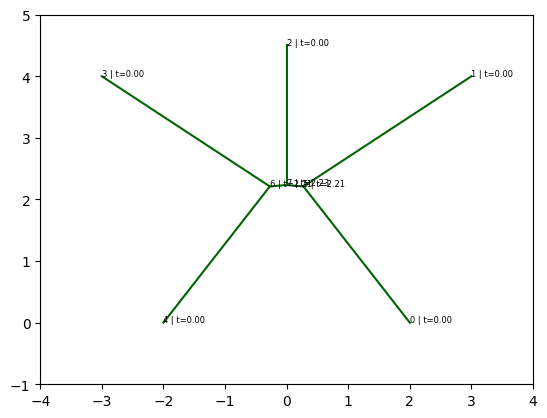

In [21]:
# Note: for py_straight_skeleton, orientation is important.
TEST_POLYGON = [(2, 0), (3, 4), (0, 4.5), (-3, 4), (-2, 0)]

skeleton = compute_skeleton(exterior=TEST_POLYGON, holes=[])

fig, ax = plt.subplots()
ax.set_xlim([-4, 4])
ax.set_ylim([-1, 5])
ax.set_aspect('equal')
py_straight_skeleton.plotting.Utils.plot_skeleton(skeleton, ax, show_vertex_info=True)

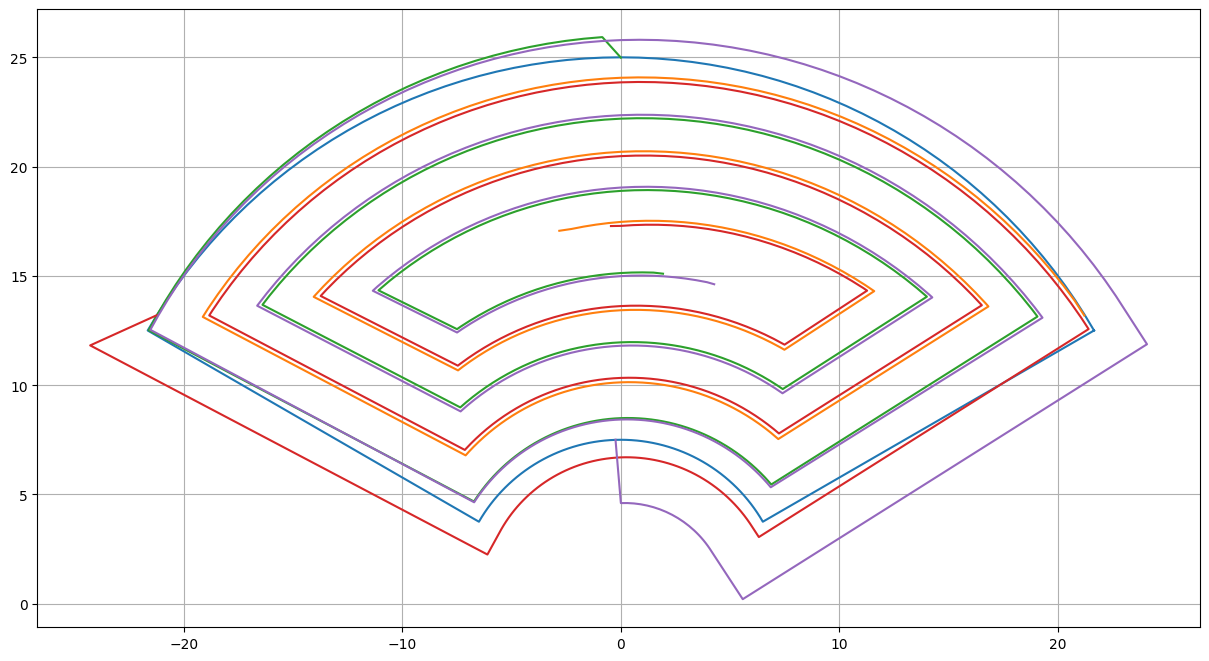

In [145]:

def interpolate(p1, p2, t, t_start, t_end):
    t_range = t_end - t_start
    t = (t - t_start) / t_range
    x1, y1 = p1
    x2, y2 = p2
    dx, dy = x2 - x1, y2 - y1
    return (x1 + t*dx, y1 + t*dy)

def approx_in_range(value, lower, upper):
    if math.isclose(value, lower) or math.isclose(value, upper):
        return True
    return lower <= value <= upper

class Skeletonator:
    def __init__(self, poly):
        self.poly = poly
        self.poly_edges = list(zip(poly, poly[1:] + poly[:1]))
        self.circumference = sum(math.dist(a, b) for a, b in self.poly_edges)
        self.skeleton = compute_skeleton(exterior=poly, holes=[])
        self.arc_map = {}
        self.divergent = set()
        self.radius = max(n.time for n in self.skeleton.nodes)
        self.min_radius = self.radius
        for n1, n2 in self.skeleton.arc_iterator():
            if n1 in self.arc_map:
                self.divergent.add(n1)
                self.min_radius = min(n1.time, self.radius)
            self.arc_map[n1] = n2
        self.node_map = dict(zip(poly, self.skeleton.nodes))

    def iter_arcs(self, p):
        start = self.node_map[p]
        while start in self.arc_map and not start in self.divergent:
            end = self.arc_map[start]
            yield start, end
            start = end

    def project_arc(self, p, r):
        t = self.radius - r

        for n0, n1 in self.iter_arcs(p):
            if t < 0 or approx_in_range(t, n0.time, n1.time):
                p0 = (n0.position.x, n0.position.y)
                p1 = (n1.position.x, n1.position.y)
                return (n0, n1), interpolate(p0, p1, t, n0.time, n1.time)

    def calc_circumference(self, r):
        projected = [self.project_arc(p, r)[1] for p in self.poly]
        return sum(math.dist(p1, p2) for p1, p2 in zip(projected, projected[1:] + projected[:1]))

    def project_point(self, t, r=None):
        t %= 1
        if r is None:
            r = self.radius
        
        t_start = 0
        p_cur = None
        for p1, p2 in self.poly_edges:
            edge_frac = math.dist(p1, p2) / self.circumference
            t_end = t_start + edge_frac
    
            if approx_in_range(t, t_start, t_end):
                p1, p2 = self.project_arc(p1, r)[1], self.project_arc(p2, r)[1]
                p_cur = interpolate(p1, p2, t, t_start, t_end)
                return p_cur

            t_start = t_end

    def do_spiral(self, t1, t2, r1=None, r2=None):
        if r1 is None:
            r1 = self.radius
        if r2 is None:
@North My big gripe with all of these old coffee cups is that they're so tiny! I've used 300ish ml coffee mugs my entire life, and I feel like I'd just never use something like that 😅             r2 = self.radius - self.min_radius

        r_interpolate = lambda t: r1 + (r2 - r1) * ((t - t1) / (t2 - t1))
            
        #yield self.project_point(t1, r1)

        edge_iter = itertools.cycle(self.poly_edges)

        circumference = self.circumference
        t_start = 0
        t = t1
        for p1, p2 in edge_iter:
            edge_frac = math.dist(p1, p2) / circumference
            t_end = t_start + edge_frac
    
            if approx_in_range(t1, t_start, t_end):
                if t2 > t_end:
                    yield self.project_arc(p2, r_interpolate(t_end))[1]
                t_start = t_end
                break

            t_start = t_end

        t_base = t_start
        t_int = 0
        t_frac = 0
        last_arc = None
        r_end = r1
        for p1, p2 in edge_iter:
            _arc, p1_proj = self.project_arc(p1, r_end)
            _arc, p2_proj = self.project_arc(p2, r_end)
            edge_frac = math.dist(p1_proj, p2_proj) / circumference
            t_start = t_int + t_frac
            t_end = t_start + edge_frac
            t_frac += edge_frac
            r_end = r_interpolate(t_end)
            
            if p2 == self.poly[0]:
                t_int += t_frac # 1
                t_frac = 0
                circumference = self.calc_circumference(r_end)
            
            if t2 > t_end:
                arc, point = self.project_arc(p2, r_end)
                if arc != last_arc:
                    last_arc = arc
                    yield point
            else:
                break

            t_start = t_end

        yield interpolate(p1_proj, p2_proj, t2, t_start, t_end)

#do_spiral(TEST_POLYGON, 0.3, 1.5)
inner_diameter = 15
outer_diameter = 50
angle = math.radians(120)
arc_tolerance = 0.05
from math import pi, ceil, sin, cos, acos
r1, r2 = inner_diameter / 2, outer_diameter/2
n1 = 64 # ceil(pi / acos(1 - arc_tolerance/inner_diameter) * angle / (2*pi))
n2 = 64 # ceil(pi / acos(1 - arc_tolerance/outer_diameter) * angle / (2*pi))
# center on y axis
pt = lambda r, a: (r*sin(a), r*cos(a))
TEST_POLYGON_2  = [pt(r2, angle/2 - i/n2 * angle) for i in range(n2+1)]
TEST_POLYGON_2 += [pt(r1, i/n1 * angle - angle/2) for i in range(n1+1)]

sk = Skeletonator(TEST_POLYGON_2)
fig, ax = plt.subplots(figsize=(15, 12))
#ax.set_xlim([-25, 25])
#ax.set_ylim([20, 60])
ax.set_aspect('equal')
poly_arr = np.array(TEST_POLYGON_2 + TEST_POLYGON_2[:1])
ax.plot(poly_arr[:,0], poly_arr[:,1])
#for r in [1.0, 0.8, 0.6, 0.4]:
#    xy = np.array(list(sk.project_point(t, r*sk.radius) for t in np.linspace(0, 1, 30)))
#    ax.plot(xy[:,0], xy[:,1], marker='o', linestyle='None')
#xy = np.array(list(sk.do_spiral(0, 9.9, sk.radius, 1)))
#ax.plot(xy[:,0], xy[:,1])
#for n in range(10):
#    v = sk.radius - n
for off in [0, 0.25, 0.5, 0.75]:
    xy = np.array(list(sk.do_spiral(off, off+2, sk.radius, 1)))
    ax.plot(xy[:,0], xy[:,1])
#py_straight_skeleton.plotting.Utils.plot_skeleton(sk.skeleton, ax)
#ax.set_xlim([-15, -10])
#ax.set_ylim([12.5, 15.0])
ax.grid()

pts = [sk.poly[0]]
for n0, n1 in sk.iter_arcs(sk.poly[0]):
    pts.append((n1.position.x, n1.position.y))
pts = np.array(pts)
#ax.plot(pts[:,0], pts[:,1], color='red')